<a href="https://colab.research.google.com/github/madewitt55/cs407-final-project/blob/Prithvi-tasks/CS407_Group_Project_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS407 — PlaylistPro Customer Churn Prediction



# Task 1 — Data Preprocessing & Exploratory Data Analysis

**What I am doing:** First I inspect the raw customer records for empty entries, duplicates, mislabeled locations, and impossible-looking numbers. Then I make graphs to see how churn varies across groups. This helps me understand my data **before** training any model.

**Task 1 deliverable:** Document the checks and cleaning rules, plus explain what each EDA graph shows.

### 1.1 Import libraries
I load packages for data analysis, graphs and machine learning. The models will be trained later, not in Task 1.

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve)

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

### 1.2 Read the CSV files
**Why:** `train.csv` includes the true cancellation answer, while `test.csv` does not. I must never pretend to know test answers. This cell checks the Colab `/content` folder, current folder, and `/mnt/data/extracted` (for downloaded copies outside Colab).

In [2]:
def locate(name):
    for folder in [Path('/content'), Path('.'), Path('/mnt/data/extracted'), Path('/mnt/data')]:
        path = folder / name
        if path.exists(): return path
    raise FileNotFoundError(f'Upload {name} in Colab Files and re-run this cell.')

train_raw = pd.read_csv(locate('train.csv'))
test_raw = pd.read_csv(locate('test.csv'))
try:
    sample_submission = pd.read_csv(locate('sample_submission.csv'))
except FileNotFoundError:
    sample_submission = None
print('Training shape:', train_raw.shape, '| Test shape:', test_raw.shape)
display(train_raw.head())
print('Training-only columns:', sorted(set(train_raw.columns) - set(test_raw.columns)))

Training shape: (125000, 20) | Test shape: (75000, 19)


,customer_id,age,location,subscription_type,payment_plan,num_subscription_pauses,payment_method,customer_service_inquiries,signup_date,weekly_hours,average_session_length,song_skip_rate,weekly_songs_played,weekly_unique_songs,num_favorite_artists,num_platform_friends,num_playlists_created,num_shared_playlists,notifications_clicked,churned
0,1,32,Montana,Free,Yearly,2,Paypal,Medium,-1606,22.391362,105.394516,0.176873,169,109,18,32,52,35,46,0
1,2,64,New Jersey,Free,Monthly,3,Paypal,Low,-2897,29.294210,52.501115,0.981811,55,163,44,33,12,25,37,1
2,3,51,Washington,Premium,Yearly,2,Credit Card,High,-348,15.400312,24.703696,0.048411,244,117,20,129,50,28,38,0
3,4,63,California,Family,Yearly,4,Apple Pay,Medium,-2894,22.842084,83.595480,0.035691,442,252,47,120,55,17,24,0
4,5,54,Washington,Family,Monthly,3,Paypal,High,-92,23.151163,52.578266,0.039738,243,230,41,66,40,32,47,0


Training-only columns: ['churned']


**What I expect to see:** The supplied data previously contained **125,000 rows × 20 columns** in training and **75,000 × 19 columns** in test. The training-only column should be `churned`. Each row represents one customer.

### 1.3 Check missing values, duplicate rows, and column types
**Why:** Missing values may need imputation. Duplicate records can distort what the model learns. Column types determine whether features need numerical scaling or categorical encoding.

In [3]:
print('Training missing values:', int(train_raw.isna().sum().sum()))
print('Test missing values:', int(test_raw.isna().sum().sum()))
print('Training duplicate rows:', int(train_raw.duplicated().sum()))
print('Training duplicate customer IDs:', int(train_raw.customer_id.duplicated().sum()))
print('Test duplicate customer IDs:', int(test_raw.customer_id.duplicated().sum()))
display(pd.DataFrame({'data_type': train_raw.dtypes.astype(str), 'missing': train_raw.isna().sum()}))

Training missing values: 0
Test missing values: 0
Training duplicate rows: 0
Training duplicate customer IDs: 0
Test duplicate customer IDs: 0


,data_type,missing
customer_id,int64,0
age,int64,0
location,object,0
subscription_type,object,0
payment_plan,object,0
num_subscription_pauses,int64,0
payment_method,object,0
customer_service_inquiries,object,0
signup_date,int64,0
weekly_hours,float64,0


**How I interpret the result:** Earlier data inspection found no missing cells and no duplicate rows in training. I still verify that using the actual files. Zero missing values does **not** mean the values themselves make sense.

### 1.4 Inspect categorical labels and fix the Nebraska typo
**What I am doing:** I compare the spellings in `location` and standardize `Nebrasksa` to `Nebraska` in **both train and test**. Otherwise a model could treat one state as two separate categories.

In [4]:
print('Before cleaning:')
print(train_raw['location'].value_counts().loc[lambda s: s.index.isin(['Nebraska','Nebrasksa'])])

train_clean = train_raw.copy()
test_clean = test_raw.copy()
for df in [train_clean, test_clean]:
    df['location'] = df['location'].replace({'Nebrasksa': 'Nebraska'})
print('After cleaning — training typo count:', (train_clean['location'] == 'Nebrasksa').sum())
print('After cleaning — test typo count:', (test_clean['location'] == 'Nebrasksa').sum())

Before cleaning:
location
Nebrasksa    6601
Name: count, dtype: int64
After cleaning — training typo count: 0
After cleaning — test typo count: 0


**What I found:** The earlier raw training file contained **6,601** `Nebrasksa` entries. I am correcting a clear category typo, not deleting those customers. If a teammate already made this correction, `.replace()` is safe to rerun.

### 1.5 Identify unusual numerical values — do not blindly overwrite them
**Why:** Inconsistent data can create misleading ratios. Here I flag cases where `weekly_unique_songs` is greater than `weekly_songs_played`. I also inspect the units of `average_session_length` and how `signup_date` is represented. Changing these without evidence could make our data worse.

In [5]:
for name, df in [('TRAIN',train_clean),('TEST',test_clean)]:
    invalid = (df.weekly_unique_songs > df.weekly_songs_played)
    print(f'{name}: unique songs > total songs: {invalid.sum():,} ({invalid.mean():.1%})')
    print(f'{name}: signup_date range: {df.signup_date.min()} to {df.signup_date.max()}')
    print(f'{name}: average_session_length range: {df.average_session_length.min():.2f} to {df.average_session_length.max():.2f}')
print('Important: do not recode the song counts or signup-date values until definitions are verified.')

TRAIN: unique songs > total songs: 36,996 (29.6%)
TRAIN: signup_date range: -2922 to -1
TRAIN: average_session_length range: 1.00 to 120.00
TEST: unique songs > total songs: 22,428 (29.9%)
TEST: signup_date range: -2922 to -1
TEST: average_session_length range: 1.00 to 120.00
Important: do not recode the song counts or signup-date values until definitions are verified.


**Interpretation:** The raw training file previously showed **36,996** song-count inconsistencies. I keep the source columns unchanged. In Task 2, I will add a **data-quality flag** and calculate the unique-song ratio **only when it is mathematically valid**. This preserves observations without pretending the inconsistent count is correct.

`average_session_length` may be measured in minutes rather than hours; confirm with the data dictionary or teammate before conversions. Negative `signup_date` values might mean days relative to a reference, but that is **not confirmed**. I will not invent an exact calendar date.

### 1.6 Target distribution — how many people churned?
**Graph:** A two-bar chart comparing customers who stayed (`0`) and churned (`1`). The bars tell me whether one outcome is much more common than the other.

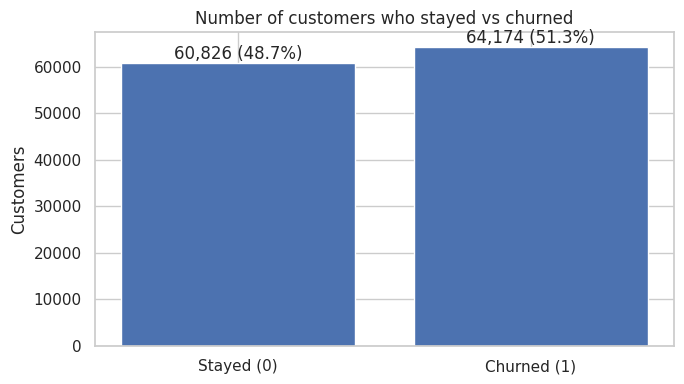

Explanation: 64,174 of 125,000 customers churned (51.3%).


In [6]:
target_counts = train_clean.churned.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(['Stayed (0)', 'Churned (1)'], [target_counts.get(0,0),target_counts.get(1,0)])
ax.set(title='Number of customers who stayed vs churned', ylabel='Customers', xlabel='')
for i,v in enumerate([target_counts.get(0,0),target_counts.get(1,0)]): ax.text(i,v, f'{v:,} ({v/len(train_clean):.1%})',ha='center',va='bottom')
plt.tight_layout(); plt.show()
print(f'Explanation: {target_counts.get(1,0):,} of {len(train_clean):,} customers churned ({target_counts.get(1,0)/len(train_clean):.1%}).')

**What I should say about this graph:** The original data had around **51.34% churned** and **48.66% stayed**, so the classes are fairly balanced. Accuracy alone is still not enough: I will also check precision, recall, F1, and ROC/PR-AUC later.

### 1.7 EDA graph — churn rate by subscription type
**Graph:** Each bar gives the **percentage who churned within that subscription type**, not the number of customers. For example, a 70% bar means approximately 70 in every 100 customers in that plan churned.

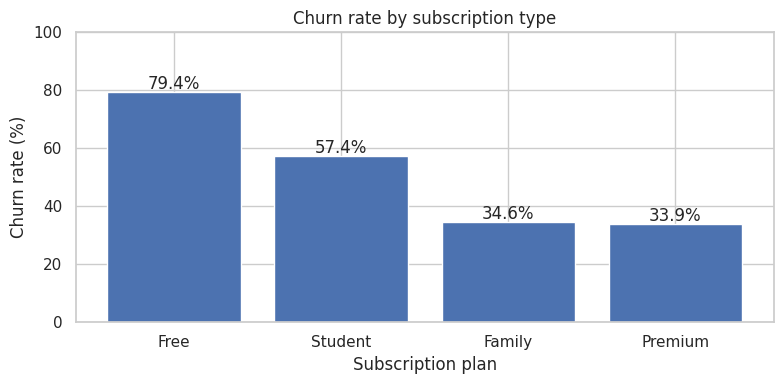

,churn_fraction,customers
subscription_type,,
Free,0.794077,31269
Student,0.573934,31305
Family,0.345810,31072
Premium,0.339095,31354


What I observe: Free has the highest observed churn rate (79.4%); Premium has the lowest (33.9%).


In [7]:
plan = train_clean.groupby('subscription_type')['churned'].agg(['mean','size']).sort_values('mean',ascending=False)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(plan.index,plan['mean']*100)
ax.set(title='Churn rate by subscription type', xlabel='Subscription plan', ylabel='Churn rate (%)',ylim=(0,100))
for i,r in enumerate(plan.itertuples()): ax.text(i,r.mean*100+1,f'{r.mean*100:.1f}%',ha='center')
plt.tight_layout();plt.show()
display(plan.rename(columns={'mean':'churn_fraction','size':'customers'}))
print(f'What I observe: {plan.index[0]} has the highest observed churn rate ({plan.iloc[0]["mean"]:.1%}); {plan.index[-1]} has the lowest ({plan.iloc[-1]["mean"]:.1%}).')

**Interpretation:** In the earlier original data, Free had approximately **79.41%** churn and Premium approximately **33.91%**. This is an **association**, not proof that being on a Free plan causes cancellation. I will test if subscription type actually helps prediction.

### 1.8 EDA graph — churn by customer service inquiries
**Graph:** Compare cancellation percentages for Low, Medium, and High support-inquiry categories. Here `customer_service_inquiries` is a **categorical label**, not the actual number of tickets.

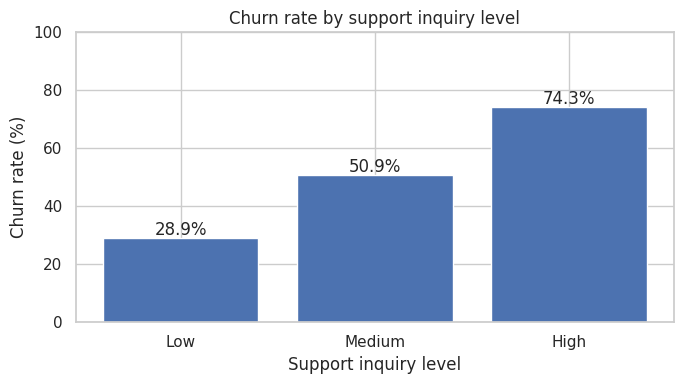

Interpretation by category:
  Low: 28.9% churn across 41,873 customers
  Medium: 50.9% churn across 41,544 customers
  High: 74.3% churn across 41,583 customers


In [8]:
support = train_clean.groupby('customer_service_inquiries')['churned'].agg(['mean','size'])
support = support.reindex([v for v in ['Low','Medium','High'] if v in support.index])
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(support.index,support['mean']*100)
ax.set(title='Churn rate by support inquiry level', xlabel='Support inquiry level', ylabel='Churn rate (%)',ylim=(0,100))
for i,r in enumerate(support.itertuples()): ax.text(i,r.mean*100+1,f'{r.mean*100:.1f}%',ha='center')
plt.tight_layout();plt.show()
print('Interpretation by category:')
for label,r in support.iterrows(): print(f'  {label}: {r["mean"]:.1%} churn across {int(r["size"]):,} customers')

**What this graph tells me:** In the earlier raw training data, Low inquiries were associated with about **28.92%** churn, Medium with **50.92%**, and High with **74.33%**. This may be a useful predictive feature, but it does not prove that contacting support causes churn.

### 1.9 EDA graph — compare listening and skip behavior
**Graph:** Three boxplots compare feature distributions among churned and retained customers. The middle line is the median; the box shows the middle half of the observations. Overlap between boxes means a single feature may not separate customers well.

/tmp/ipykernel_1852/4053225761.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([train_clean.loc[train_clean.churned==0,col].dropna(),train_clean.loc[train_clean.churned==1,col].dropna()],labels=['Stayed','Churned'],showfliers=False)
/tmp/ipykernel_1852/4053225761.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([train_clean.loc[train_clean.churned==0,col].dropna(),train_clean.loc[train_clean.churned==1,col].dropna()],labels=['Stayed','Churned'],showfliers=False)
/tmp/ipykernel_1852/4053225761.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([train_clean.loc[train_clean.churne

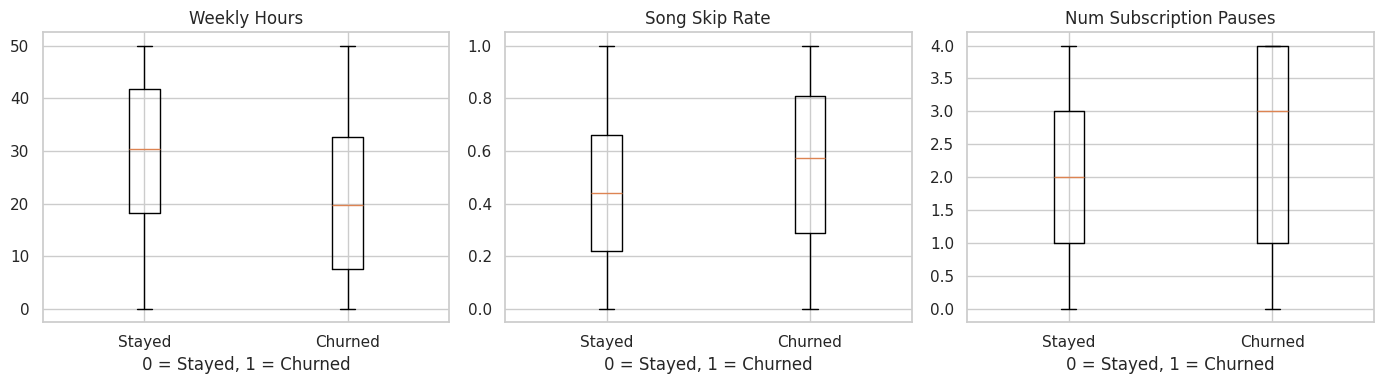

weekly_hours: stayed mean=29.53; churned mean=20.78
song_skip_rate: stayed mean=0.45; churned mean=0.55
num_subscription_pauses: stayed mean=1.72; churned mean=2.24


In [9]:
eda_cols=['weekly_hours','song_skip_rate','num_subscription_pauses']
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col in zip(axes,eda_cols):
    ax.boxplot([train_clean.loc[train_clean.churned==0,col].dropna(),train_clean.loc[train_clean.churned==1,col].dropna()],labels=['Stayed','Churned'],showfliers=False)
    ax.set_title(col.replace('_',' ').title());ax.set_xlabel('0 = Stayed, 1 = Churned')
plt.tight_layout();plt.show()
for col in eda_cols:
    means=train_clean.groupby('churned')[col].mean()
    print(f'{col}: stayed mean={means.get(0):.2f}; churned mean={means.get(1):.2f}')

**How to explain the boxplots:** I check whether typical listening hours, skipping, or pausing differ between groups. If the boxes overlap a lot, that feature by itself may not tell us who will churn. The printed averages give me real values instead of guessing from the chart. Correlation is not causation.

# Task 2 — Feature Engineering

**What I am doing:** I turn existing columns into additional signals about engagement, pausing, social activity, and data quality. I apply **the same rules to training and test data** and do not use `churned` in the calculations. These features are hypotheses, not guaranteed improvements.

**Important:** To avoid making unjustified assumptions, I do not convert uncertain signup dates to an absolute date, do not invent support ticket counts, and do not force invalid unique-song ratios to a made-up number.

### 2.1 My feature-engineering ideas, formulas, and reasons

Feature engineering means creating useful new columns from information already in the dataset. I want to test whether combinations of listening, social, subscription and notification behavior can help predict churn. **A new feature is a hypothesis—not proof of predictive value.**

| Feature | How I calculate it | Why I added it |
|---|---|---|
| `has_paused` | 1 if subscription pauses > 0 | Marks customers with a history of interrupted subscriptions |
| `songs_per_hour` | weekly songs / weekly listening hours | Measures listening intensity |
| `skip_adjusted_songs` | songs × (1 − skip rate) | Estimates songs not skipped; proxy, not exact completed plays |
| `playlist_activity` | created + shared playlists | Combines ways users interact with playlists |
| `social_engagement` | friends + shared playlists | Captures a simple measure of social involvement |
| `shares_per_friend` | shared playlists / (friends + 1) | Compares sharing behavior relative to friend count |
| `playlist_share_fraction` | shared / (created + shared + 1) | Separates people who share from people who primarily create |
| `has_high_skip_and_low_hours` | 1 if skip rate > 0.5 **and** hours < 10 | Tests whether two potential disengagement signals together matter |
| `notifications_per_hour` | notification clicks / (weekly hours + 1) | Captures notification response relative to usage |
| `is_free_plan` | 1 for Free subscribers | Tests whether Free status adds a simple indicator |
| `plan_listening_group` | subscription plan + a low/high weekly-hours label | Tests whether engagement may behave differently across plans |
| `song_count_inconsistent` | 1 if unique songs > played songs, or invalid denominator | Flags questionable data rather than inventing corrected song counts |
| `unique_song_ratio` | unique songs / songs played only when counts are valid | Measures variety for logically consistent observations |
| `signup_age_proxy_days` (OFF by default) | negative of signup date | Could represent tenure, **only if the data documentation confirms negative-day offsets** |

**Data-quality choices:** The Nebraska typo is corrected in Task 1. We do not arbitrarily change questionable song counts. We treat missing engineered ratios through imputation in the model pipeline. We don't convert average-session units without confirming their meaning.

**About external state income:** State-level Census median household income is a promising separate experiment, but I have not added it because it needs an approved source, year, reliable state merge, and instructor approval. It is not a customer's personal income.

**About thresholds:** The 0.5 skip-rate and 10-hour cutoffs are transparent exploratory defaults, not optimized thresholds. They can be revised later using training-only validation.

In [10]:
USE_SIGNUP_DAY_PROXY = False  # Enable only if signup_date is confirmed as negative elapsed days.

def engineer_features(df):
    df = df.copy()
    df['has_paused'] = (df['num_subscription_pauses'] > 0).astype(int)
    hours = df['weekly_hours'].where(df['weekly_hours'] > 0, np.nan)
    df['songs_per_hour'] = df['weekly_songs_played'] / hours
    df['skip_adjusted_songs'] = df['weekly_songs_played'] * (1 - df['song_skip_rate'])
    df['playlist_activity'] = df['num_playlists_created'] + df['num_shared_playlists']
    df['social_engagement'] = df['num_platform_friends'] + df['num_shared_playlists']
    df['shares_per_friend'] = df['num_shared_playlists'] / (df['num_platform_friends'] + 1)
    df['playlist_share_fraction'] = df['num_shared_playlists'] / (df['playlist_activity'] + 1)
    df['has_high_skip_and_low_hours'] = ((df['song_skip_rate'] > 0.5) & (df['weekly_hours'] < 10)).astype(int)
    df['notifications_per_hour'] = df['notifications_clicked'] / (df['weekly_hours'] + 1)
    df['is_free_plan'] = (df['subscription_type'] == 'Free').astype(int)
    df['plan_listening_group'] = (df['subscription_type'].astype(str) + '_' +
        np.where(df['weekly_hours'] < 10, 'LowHours', 'OtherHours'))
    invalid = ((df['weekly_unique_songs'] > df['weekly_songs_played']) |
               (df['weekly_songs_played'] <= 0) | (df['weekly_unique_songs'] < 0))
    df['song_count_inconsistent'] = invalid.astype(int)
    df['unique_song_ratio'] = np.where(~invalid,
        df['weekly_unique_songs'] / df['weekly_songs_played'].replace(0, np.nan), np.nan)
    if USE_SIGNUP_DAY_PROXY:
        df['signup_age_proxy_days'] = -df['signup_date']
    return df

train_fe = engineer_features(train_clean)
test_fe = engineer_features(test_clean)
engineered_cols = sorted(set(train_fe.columns) - set(train_clean.columns))
print('New engineered features:', engineered_cols)
display(train_fe[engineered_cols + ['churned']].head())
print('Engineered-feature missing values:')
display(train_fe[engineered_cols].isna().sum())

New engineered features: ['has_high_skip_and_low_hours', 'has_paused', 'is_free_plan', 'notifications_per_hour', 'plan_listening_group', 'playlist_activity', 'playlist_share_fraction', 'shares_per_friend', 'skip_adjusted_songs', 'social_engagement', 'song_count_inconsistent', 'songs_per_hour', 'unique_song_ratio']


,has_high_skip_and_low_hours,has_paused,is_free_plan,notifications_per_hour,plan_listening_group,playlist_activity,playlist_share_fraction,shares_per_friend,skip_adjusted_songs,social_engagement,song_count_inconsistent,songs_per_hour,unique_song_ratio,churned
0,0,1,1,1.966538,Free_OtherHours,87,0.397727,1.060606,139.108484,67,0,7.547554,0.644970,0
1,0,1,1,1.221355,Free_OtherHours,37,0.657895,0.735294,1.000403,58,1,1.877504,NaN,1
2,0,1,0,2.317029,Premium_OtherHours,78,0.354430,0.215385,232.187706,157,0,15.843835,0.479508,0
3,0,1,0,1.006623,Family_OtherHours,72,0.232877,0.140496,426.224473,137,0,19.350248,0.570136,0
4,0,1,0,1.946076,Family_OtherHours,72,0.438356,0.477612,233.343691,98,0,10.496233,0.946502,0


Engineered-feature missing values:


,0
has_high_skip_and_low_hours,0
has_paused,0
is_free_plan,0
notifications_per_hour,0
plan_listening_group,0
playlist_activity,0
playlist_share_fraction,0
shares_per_friend,0
skip_adjusted_songs,0
social_engagement,0


**Interpretation:** New missing values in `unique_song_ratio` are **intentional**: I cannot compute a reliable ratio when total songs are zero or when unique songs exceed total songs. The modeling pipeline in Task 3 will impute them from the **training fold only**.

### 2.2 Graph engineered features vs churn
**Graph:** I compare feature averages for churned and retained customers. Different means suggest a potential pattern, but they do **not** guarantee the feature improves validation performance.

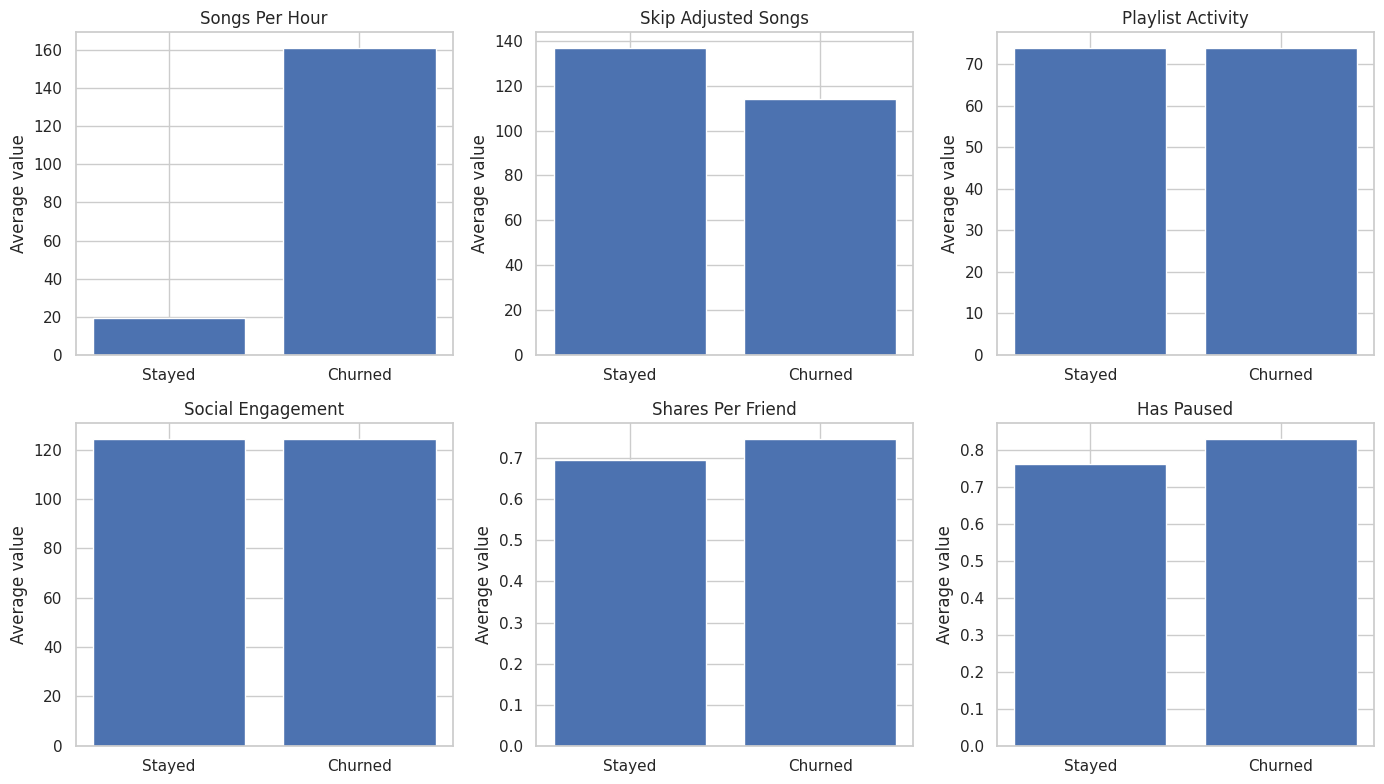

churned,Stayed (0),Churned (1)
songs_per_hour,19.452003,161.248609
skip_adjusted_songs,137.003502,114.280986
playlist_activity,74.020600,74.004379
social_engagement,124.388551,124.152694
shares_per_friend,0.696770,0.747417
has_paused,0.762437,0.829947


Interpretation: Look for which engineered features have different averages. I will confirm usefulness by testing model performance, not by visual difference alone.


In [11]:
show_cols=['songs_per_hour','skip_adjusted_songs','playlist_activity','social_engagement','shares_per_friend','has_paused']
means=train_fe.groupby('churned')[show_cols].mean().T
fig,axs=plt.subplots(2,3,figsize=(14,8))
for ax,col in zip(axs.flat,show_cols):
    ax.bar(['Stayed','Churned'],means.loc[col].values)
    ax.set_title(col.replace('_',' ').title());ax.set_ylabel('Average value')
plt.tight_layout();plt.show()
display(means.rename(columns={0:'Stayed (0)',1:'Churned (1)'}))
print('Interpretation: Look for which engineered features have different averages. I will confirm usefulness by testing model performance, not by visual difference alone.')

### 2.3 Additional feature graph: which risk signals show higher churn?

**What I am doing:** I compare the percentage of customers who churned among those flagged for **both high skipping and low listening** versus everyone else.

**How to read the graph:** Taller bars mean a higher proportion of customers in that group churned. The calculation uses the actual dataset, so I will interpret the displayed percentages rather than assuming which group wins.

**Why it matters:** A combination of behaviors might reveal a pattern that either behavior alone misses. This shows association, not causation.

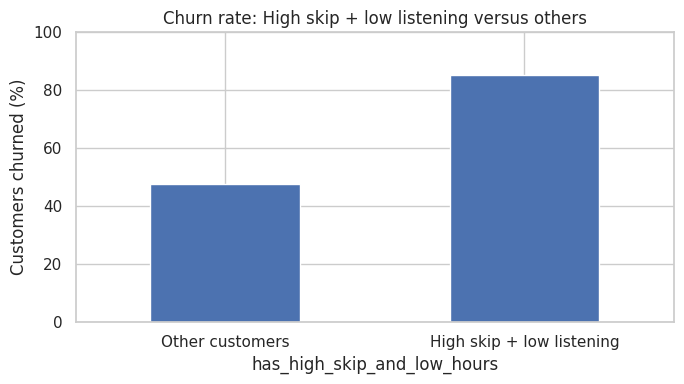

Churn percentages in each group:


,churned
has_high_skip_and_low_hours,
Other customers,47.57
High skip + low listening,85.33


Interpretation: Compare the two printed percentages; a difference is an observed association, not proof of cause.


In [12]:
risk_rate = (train_fe.groupby('has_high_skip_and_low_hours')['churned'].mean() * 100).reindex([0, 1])
ax = risk_rate.plot(kind='bar', figsize=(7,4), title='Churn rate: High skip + low listening versus others')
ax.set_xticklabels(['Other customers', 'High skip + low listening'], rotation=0)
ax.set_ylabel('Customers churned (%)')
ax.set_ylim(0,100)
plt.tight_layout(); plt.show()
print('Churn percentages in each group:')
display(risk_rate.rename({0:'Other customers',1:'High skip + low listening'}).round(2))
print('Interpretation: Compare the two printed percentages; a difference is an observed association, not proof of cause.')

### 2.3 Graph of unique-song data quality
**Graph:** This shows how often invalid unique-song counts appear in each churn group. It is a quality check, **not** evidence that errors cause churn.

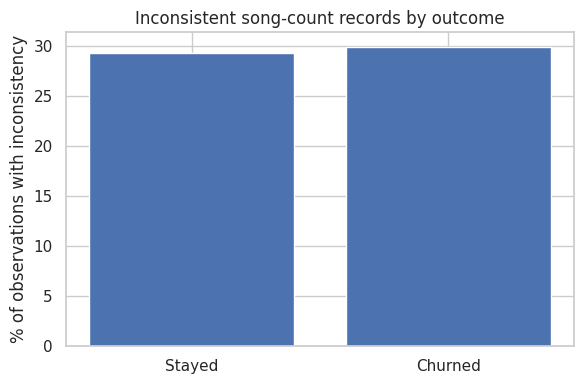

Invalid song-count percentage by class:


,song_count_inconsistent
churned,
0,29.304903
1,29.873469


In [13]:
invalid_pct=train_fe.groupby('churned')['song_count_inconsistent'].mean()*100
fig,ax=plt.subplots(figsize=(6,4))
ax.bar(['Stayed','Churned'],[invalid_pct.get(0,0),invalid_pct.get(1,0)])
ax.set(title='Inconsistent song-count records by outcome',ylabel='% of observations with inconsistency')
plt.tight_layout();plt.show()
print('Invalid song-count percentage by class:');display(invalid_pct)

# Task 3 — Model Selection and Training

**What I am doing:** I train a **baseline Logistic Regression**, **k-nearest neighbors (KNN)**, and a **Random Forest**. Models learn on one portion of training data and are evaluated on a separate validation portion. I use a pipeline so imputation, one-hot encoding and scaling are **fitted inside the training fold** rather than peeking at held-out data.

**Why not use `customer_id`?** It is an identifier, not a meaningful behavior feature; a model could memorize arbitrary ID patterns. I also exclude `churned`, which is the answer we are trying to predict.

### 3.1 Choose inputs, output, and split
I use a stratified 80/20 holdout so both groups retain roughly the same churn proportions. No Kaggle test labels are available.

In [14]:
TARGET='churned'
DROP_COLUMNS=['customer_id']
# Keep original numeric/categorical fields, adding engineered features.
X=train_fe.drop(columns=DROP_COLUMNS+[TARGET])
y=train_fe[TARGET].astype(int)
X_test=test_fe.drop(columns=DROP_COLUMNS)
assert list(X.columns)==list(X_test.columns), 'Train/test feature columns differ.'
X_train,X_valid,y_train,y_valid=train_test_split(X,y,test_size=0.20,stratify=y,random_state=RANDOM_STATE)
print('Train split:',X_train.shape,'| Validation split:',X_valid.shape)
print('Churn rate: train',round(y_train.mean(),4),'| validation',round(y_valid.mean(),4))

Train split: (100000, 31) | Validation split: (25000, 31)
Churn rate: train 0.5134 | validation 0.5134


### 3.2 Preprocessing pipeline — no leakage
**Numeric columns:** fill missing values with the median learned only from the training fold, then standardize values for KNN/Logistic Regression. **Categorical columns:** fill missing labels and one-hot encode categories such as Free/Premium and location. Encoders ignore previously unseen categories in validation/test.

In [15]:
numeric_columns=X.select_dtypes(include=np.number).columns.tolist()
categorical_columns=X.select_dtypes(exclude=np.number).columns.tolist()
try:
    encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=True)
except TypeError:
    encoder=OneHotEncoder(handle_unknown='ignore',sparse=True)
preprocess=ColumnTransformer([
    ('num', Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric_columns),
    ('cat', Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',encoder)]),categorical_columns)
])
print('Numeric columns:',len(numeric_columns),'| Categorical columns:',categorical_columns)

Numeric columns: 25 | Categorical columns: ['location', 'subscription_type', 'payment_plan', 'payment_method', 'customer_service_inquiries', 'plan_listening_group']


### 3.3 Define the three classifiers
- **Logistic Regression:** interpretable baseline probabilities.
- **KNN:** predicts based on similar customers after scaling.
- **Random Forest:** combines many decision trees to model complex relationships.

My Random Forest is capped in size to keep the Colab run practical. I can tune models later after reviewing cross-validation.

In [16]:
model_specs={
    'Logistic Regression': LogisticRegression(max_iter=700,random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Random Forest': RandomForestClassifier(n_estimators=120,min_samples_leaf=5,n_jobs=-1,random_state=RANDOM_STATE)
}
models={name:Pipeline([('preprocess',clone(preprocess)),('classifier',clone(clf))]) for name,clf in model_specs.items()}
print('Models prepared:',list(models))

Models prepared: ['Logistic Regression', 'KNN', 'Random Forest']


### 3.4 Train the models — this completes Task 3

**What I am doing:** I train Logistic Regression and Random Forest on the training customers. KNN is slower on large data, so for a practical first experiment I fit KNN on a **stratified sample of 20,000 training customers**, and I clearly record that difference. All models use preprocessing fitted on their respective training data only.

**What training means:** The model learns patterns between customer features and known `churned` outcomes. It does **not** learn from the hidden Kaggle test labels.

**What to look for:** Each training run prints a confirmation. This cell does **not** calculate validation performance; we leave that for Task 4.

In [17]:
print('Training Logistic Regression on all training rows...')
models['Logistic Regression'].fit(X_train, y_train)
print('Logistic Regression trained.')

print('Training Random Forest on all training rows...')
models['Random Forest'].fit(X_train, y_train)
print('Random Forest trained.')

X_knn_train, _, y_knn_train, _ = train_test_split(
    X_train, y_train, train_size=20000, random_state=RANDOM_STATE, stratify=y_train
)
print('Training KNN on 20,000 stratified training rows...')
models['KNN'].fit(X_knn_train, y_knn_train)
print('KNN trained.')
print('Task 3 training complete. Evaluation is reserved for Task 4.')

Training Logistic Regression on all training rows...
Logistic Regression trained.
Training Random Forest on all training rows...
Random Forest trained.
Training KNN on 20,000 stratified training rows...
KNN trained.
Task 3 training complete. Evaluation is reserved for Task 4.


### 3.5 My Task 3 summary

I separated `churned` from the other columns, removed `customer_id`, and held out 20% of labeled customers for later validation. I used a preprocessing pipeline so numerical imputation/scaling and categorical one-hot encoding are learned from training data only. I built and trained Logistic Regression, KNN, and Random Forest classifiers. KNN used a smaller stratified training sample because of its computational cost, which I will disclose when interpreting comparisons.

I have **not yet evaluated the models or chosen a winner**. I will do that in Task 4.

# TASK 4 — MODEL EVALUATION AND INTERPRETATION



# TASK 5 — FINAL REPORT, RECOMMENDATIONS AND KAGGLE SUBMISSION

